# Laboratorio 2: Simulación e Inferencia — Airbnb Nueva York
**INF280 Estadística Computacional, UTFSM — Grupo 25**
Integrantes: José Flores, Sebastian Alcaide, Pedro Ortiz y Miguel Primera

**Pregunta:** ¿cuánto difieren las calificaciones medias de los anuncios de Manhattan y Brooklyn, y con qué precisión podemos estimarlo?

**Uso de IA:** *(editar: indicar qué herramientas se usaron y para qué, por ejemplo "ChatGPT/Codex: apoyo en código del bootstrap y Monte Carlo; Claude: revisión y simplificación del notebook")*. El grupo revisó y comprende cada línea.

| Parte del enunciado | Sección |
|---|---|
| 2.1 Estimación puntual | 2 y 3 |
| 2.2 Bootstrap (propio) | 4 |
| 2.3 Monte Carlo | 5 |
| Interpretación y conclusiones | 6 |

In [1]:
# 1. Herramientas y constantes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

SEED = 2026          # semilla: permite repetir los resultados
B = 10_000           # remuestras bootstrap
R = 10_000           # realizaciones Monte Carlo por escenario
rng = np.random.default_rng(SEED)

## 1. Datos
Usamos el mismo dataset de la Entrega 1 (*Airbnb Open Data NYC*, Kaggle). Aplicamos solo la limpieza que importa para esta pregunta: eliminar filas duplicadas, corregir dos nombres de distrito mal escritos (`manhatan`, `brookln`) y quedarnos con los anuncios que tienen distrito **y** calificación (`review_rate_number`, escala 1 a 5). No se imputan calificaciones.

In [2]:
# 2. Cargar y limpiar
ruta = next((p for p in [Path('data/Airbnb_Open_Data.csv'), Path('Airbnb_Open_Data.csv')] if p.is_file()), None)
if ruta is None:                                   # alternativa: descargar desde Kaggle
    import kagglehub
    ruta = Path(kagglehub.dataset_download('arianazmoudeh/airbnbopendata')) / 'Airbnb_Open_Data.csv'

raw = pd.read_csv(ruta, low_memory=False)
df = raw.drop_duplicates().copy()
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df['neighbourhood_group'] = df['neighbourhood_group'].replace({'manhatan': 'Manhattan', 'brookln': 'Brooklyn'})

pares = df[['neighbourhood_group', 'review_rate_number']].dropna()
M = pares.loc[pares['neighbourhood_group'] == 'Manhattan', 'review_rate_number'].to_numpy()
K = pares.loc[pares['neighbourhood_group'] == 'Brooklyn',  'review_rate_number'].to_numpy()

print('Filas originales:', len(raw), '| sin duplicados:', len(df), '| con distrito y nota:', len(pares))
print('Manhattan:', len(M), 'anuncios | Brooklyn:', len(K), 'anuncios')

Filas originales: 102599 | sin duplicados: 102058 | con distrito y nota: 101712
Manhattan: 43418 anuncios | Brooklyn: 41515 anuncios


## 2. Parámetros de interés y conexión con la Entrega 1
En la Entrega 1 el ANOVA indicó que la calificación media **varía entre distritos**. Aquí cuantificamos el contraste entre los dos distritos con más anuncios. Los parámetros son:

$$\mu_M = E(Y \mid \text{Manhattan}), \qquad \mu_B = E(Y \mid \text{Brooklyn}), \qquad \Delta = \mu_M - \mu_B$$

donde $Y$ es la calificación (1 a 5). Son pertinentes porque pasan de "¿hay diferencias?" (Entrega 1) a "¿de qué tamaño es la diferencia y qué tan precisa es su estimación?". Elegimos estos distritos por su tamaño, no por tener las medias más extremas.

## 3. Estimación puntual
Estimadores: $\hat\mu_g=\bar Y_g$ y $\hat\Delta=\bar Y_M-\bar Y_B$. Error estándar (EE):

$$\widehat{EE}(\bar Y_g)=\frac{s_g}{\sqrt{n_g}},\qquad \widehat{EE}(\hat\Delta)=\sqrt{\frac{s_M^2}{n_M}+\frac{s_B^2}{n_B}}$$

**Propiedades:** la media muestral es **insesgada** ($E(\bar Y)=\mu$), **consistente** (converge a $\mu$ cuando $n$ crece, por la ley de los grandes números) y **eficiente** entre los estimadores lineales insesgados (tiene varianza $\sigma^2/n$, la mínima). Esto supone observaciones independientes y una muestra representativa del parámetro objetivo.

In [3]:
# 3. Estimaciones puntuales y IC clásico del 95%
def resumen_media(x):
    n = len(x)
    media = x.mean()
    ee = x.std(ddof=1) / np.sqrt(n)
    q = stats.t.ppf(0.975, n - 1)
    return media, ee, media - q * ee, media + q * ee

mu_m, ee_m, lo_m, hi_m = resumen_media(M)
mu_b, ee_b, lo_b, hi_b = resumen_media(K)

delta = mu_m - mu_b
ee_delta = np.sqrt(ee_m**2 + ee_b**2)
lo_d, hi_d = delta - 1.96 * ee_delta, delta + 1.96 * ee_delta   # n grande: cuantil normal

clasico = pd.DataFrame({'estimacion': [mu_m, mu_b, delta],
                        'EE': [ee_m, ee_b, ee_delta],
                        'IC95_inf': [lo_m, lo_b, lo_d],
                        'IC95_sup': [hi_m, hi_b, hi_d]},
                       index=['Media Manhattan', 'Media Brooklyn', 'Diferencia M-B'])
clasico.round(4)

,estimacion,EE,IC95_inf,IC95_sup
Media Manhattan,3.2765,0.0062,3.2644,3.2887
Media Brooklyn,3.2585,0.0064,3.2460,3.2709
Diferencia M-B,0.0181,0.0089,0.0007,0.0355


## 4. Bootstrap

### 4.1 Origen, motivación y relevancia
Lo propuso **Bradley Efron en 1979**. Idea: la muestra que tenemos es nuestra mejor aproximación de la población, así que **remuestreamos desde ella** para ver cuánto variaría un estimador si repitiéramos el muestreo. Sirve cuando no hay (o es difícil obtener) una fórmula para el error de un estadístico, como una mediana, un cuantil o un coeficiente de regresión. Hoy es una herramienta estándar para obtener errores estándar e intervalos con poco supuesto distribucional.

### 4.2 Pasos del procedimiento
1. Calcular el estimador en la muestra original.
2. Sortear **con reemplazo** una remuestra del **mismo tamaño** que la original (en cada distrito por separado).
3. Calcular el estimador en la remuestra.
4. Repetir los pasos 2 y 3 $B$ veces.
5. Usar la desviación estándar de las $B$ réplicas como EE y sus percentiles 2,5 y 97,5 como IC del 95%.

*Ejemplo:* si los datos son `[1, 3, 5]`, una remuestra posible es `[5, 5, 1]`: mismo tamaño, un dato repetido y otro ausente.

In [4]:
# 4. Bootstrap propio (sin librerías de bootstrap)
def bootstrap(x, y, B, rng):
    # Devuelve un arreglo (B, 3): media de x, media de y y su diferencia en cada remuestra.
    res = np.empty((B, 3))
    for b in range(B):
        xb = x[rng.integers(0, len(x), len(x))]   # sorteo con reemplazo, mismo tamaño
        yb = y[rng.integers(0, len(y), len(y))]
        res[b] = xb.mean(), yb.mean(), xb.mean() - yb.mean()
    return res

boot = bootstrap(M, K, B, np.random.default_rng(SEED))

boot_tabla = pd.DataFrame({'estimacion': [mu_m, mu_b, delta],
                           'EE_boot': boot.std(axis=0, ddof=1),
                           'IC95_inf': np.percentile(boot, 2.5, axis=0),
                           'IC95_sup': np.percentile(boot, 97.5, axis=0)},
                          index=clasico.index)
boot_tabla.round(4)

,estimacion,EE_boot,IC95_inf,IC95_sup
Media Manhattan,3.2765,0.0062,3.2645,3.2888
Media Brooklyn,3.2585,0.0063,3.2462,3.2708
Diferencia M-B,0.0181,0.0088,0.0011,0.0355


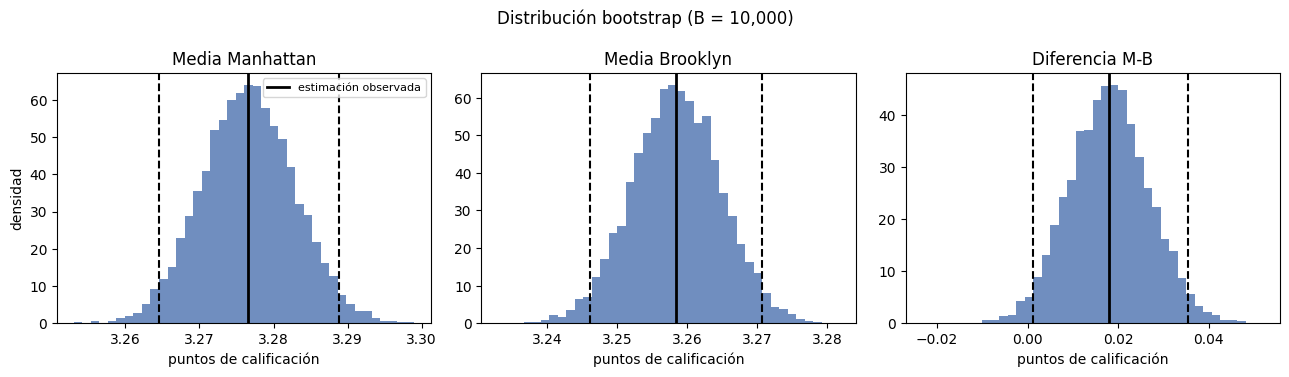

In [5]:
# 5. Distribución de los estadísticos bootstrap
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for j, (ax, nombre) in enumerate(zip(axes, clasico.index)):
    ax.hist(boot[:, j], bins=40, density=True, color='#4c72b0', alpha=0.8)
    ax.axvline(clasico.iloc[j]['estimacion'], color='k', lw=2, label='estimación observada')
    for q in (2.5, 97.5):
        ax.axvline(np.percentile(boot[:, j], q), color='k', ls='--')
    ax.set_title(nombre); ax.set_xlabel('puntos de calificación')
axes[0].set_ylabel('densidad'); axes[0].legend(fontsize=8)
fig.suptitle(f'Distribución bootstrap (B = {B:,})'); fig.tight_layout(); plt.show()

### 4.3 Comparación con la estimación clásica

In [6]:
# 6. Clásico vs bootstrap, y estabilidad según B
comp = pd.DataFrame({'EE_clasico': clasico['EE'], 'EE_bootstrap': boot_tabla['EE_boot']})
comp['razon_boot/clasico'] = comp['EE_bootstrap'] / comp['EE_clasico']
display(comp.round(5))
print(f"IC95 diferencia | clásico: [{lo_d:.4f}, {hi_d:.4f}] | bootstrap: "
      f"[{boot_tabla.iloc[2]['IC95_inf']:.4f}, {boot_tabla.iloc[2]['IC95_sup']:.4f}]")

# estabilidad: EE bootstrap de la diferencia usando las primeras b réplicas
estab = pd.DataFrame({'B': [200, 1000, 5000, B], 'EE_diferencia': [boot[:b, 2].std(ddof=1) for b in [200, 1000, 5000, B]]})
display(estab.round(5))

,EE_clasico,EE_bootstrap,razon_boot/clasico
Media Manhattan,0.00619,0.00623,1.00591
Media Brooklyn,0.00636,0.00630,0.99133
Diferencia M-B,0.00888,0.00883,0.99481


IC95 diferencia | clásico: [0.0007, 0.0355] | bootstrap: [0.0011, 0.0355]


,B,EE_diferencia
0,200,0.00911
1,1000,0.00887
2,5000,0.00870
3,10000,0.00883


**¿Hay diferencias relevantes entre ambos enfoques?** No: los EE y los intervalos casi coinciden (razón cercana a 1). Es lo esperable, porque el estimador es una media y las muestras son muy grandes (Teorema Central del Límite).

**Ventajas del bootstrap:** muestra la distribución completa del estimador, no exige fórmula ni normalidad, y se extiende a estadísticos sin fórmula simple (mediana, proporciones, cuantiles).
**Limitaciones:** depende de que la muestra sea representativa y de observaciones independientes (no corrige sesgo de selección ni dependencia); el resultado tiene un pequeño error numérico por usar $B$ finito, que se estabiliza al aumentar $B$ (tabla anterior); y requiere más cómputo que la fórmula.

## 5. Simulación Monte Carlo

### 5.1 Idea general
Monte Carlo aproxima cantidades difíciles de calcular analíticamente generando **muchas realizaciones aleatorias de un modelo** y observando con qué frecuencia ocurre un evento o cómo se comporta un estadístico. Su propósito aquí es estudiar el comportamiento de un procedimiento estadístico bajo condiciones controladas.

### 5.2 Situación de interés
**¿Con cuántos anuncios por distrito podríamos detectar una diferencia como la observada, y qué tan estable sería su estimación?** Es decir, estudiar cómo cambian la potencia de la prueba y la precisión del estimador al variar el tamaño muestral.

### 5.3 Modelo
- **Variable:** calificación $Y\in\{1,2,3,4,5\}$ de cada anuncio.
- **Supuestos:** anuncios independientes; en cada distrito, la calificación sigue una distribución categórica con probabilidades iguales a las **frecuencias observadas** (así el modelo respeta la escala discreta y está informado por los datos); esas probabilidades se mantienen fijas.
- **Generación:** para $n$ anuncios, los conteos de cada nota siguen una Multinomial$(n, p_1,\dots,p_5)$; de ahí se obtiene la media simulada.
- **Dos condiciones:** *modelo ajustado* (cada distrito con su distribución, diferencia real $=\hat\Delta$) y *modelo nulo* (ambos distritos con la misma distribución, diferencia real $=0$), que sirve de control para los falsos rechazos.
- **Evento de interés:** que la prueba de diferencia de medias (estadístico $|\hat\Delta/\widehat{EE}|>1{,}96$, aproximación normal) rechace igualdad de medias.

In [7]:
# 7. Probabilidades del modelo y función de simulación
valores = np.arange(1, 6)
cuentas_m = np.bincount(M.astype(int), minlength=6)[1:]
cuentas_b = np.bincount(K.astype(int), minlength=6)[1:]
p_m = cuentas_m / cuentas_m.sum()
p_b = cuentas_b / cuentas_b.sum()
p_comun = (cuentas_m + cuentas_b) / (cuentas_m.sum() + cuentas_b.sum())
display(pd.DataFrame({'nota': valores, 'p_Manhattan': p_m, 'p_Brooklyn': p_b, 'p_comun (nulo)': p_comun}).round(4))

def simular(n_m, n_b, p1, p2, R, rng):
    # Genera R pares de muestras (como conteos) y devuelve la diferencia de medias y si se rechaza H0.
    c1 = rng.multinomial(n_m, p1, size=R)            # conteos de notas 1..5 de cada muestra
    c2 = rng.multinomial(n_b, p2, size=R)
    m1, m2 = c1 @ valores / n_m, c2 @ valores / n_b  # medias simuladas
    v1 = (c1 @ valores**2 - n_m * m1**2) / (n_m - 1) # varianzas muestrales
    v2 = (c2 @ valores**2 - n_b * m2**2) / (n_b - 1)
    dif = m1 - m2
    ee = np.sqrt(v1 / n_m + v2 / n_b)
    return dif, np.abs(dif / ee) > 1.96

,nota,p_Manhattan,p_Brooklyn,p_comun (nulo)
0,1,0.0928,0.0966,0.0947
1,2,0.2237,0.2278,0.2257
2,3,0.2283,0.2211,0.2248
3,4,0.2244,0.2295,0.2269
4,5,0.2307,0.2250,0.2279


In [8]:
# 8. Escenarios: tamaño muestral por distrito
escenarios = {'50': (50, 50), '200': (200, 200), '1000': (1000, 1000), '5000': (5000, 5000),
              'original': (len(M), len(K))}
rng_mc = np.random.default_rng(SEED + 1)
filas, sims = [], {}
for nombre, (n1, n2) in escenarios.items():
    dif_a, rech_a = simular(n1, n2, p_m, p_b, R, rng_mc)        # modelo ajustado
    dif_n, rech_n = simular(n1, n2, p_comun, p_comun, R, rng_mc) # modelo nulo
    sims[nombre] = dif_a
    filas.append([nombre, rech_a.mean(), rech_n.mean(), dif_a.std(), (np.abs(dif_a - delta) <= 0.05).mean(), (dif_a > 0).mean()])

mc = pd.DataFrame(filas, columns=['escenario', 'potencia', 'falsos_rechazos', 'DE_diferencia',
                                  'P(error<=0.05)', 'P(dif>0)']).set_index('escenario')
mc.round(4)

,potencia,falsos_rechazos,DE_diferencia,P(error<=0.05),P(dif>0)
escenario,,,,,
50,0.0504,0.0532,0.2587,0.1556,0.5160
200,0.0527,0.0510,0.1289,0.3003,0.5469
1000,0.0597,0.0489,0.0579,0.6106,0.6221
5000,0.1103,0.0493,0.0261,0.9452,0.7583
original,0.5298,0.0481,0.0090,1.0000,0.9769


### 5.4 Número de simulaciones
Para una probabilidad estimada con $R$ realizaciones independientes, el error estándar Monte Carlo es $\sqrt{\hat p(1-\hat p)/R}\le 1/(2\sqrt R)$. Con $R=10.000$ es como máximo **0,005** (0,5 puntos porcentuales). Comprobamos además que la estimación se estabiliza al acumular realizaciones.

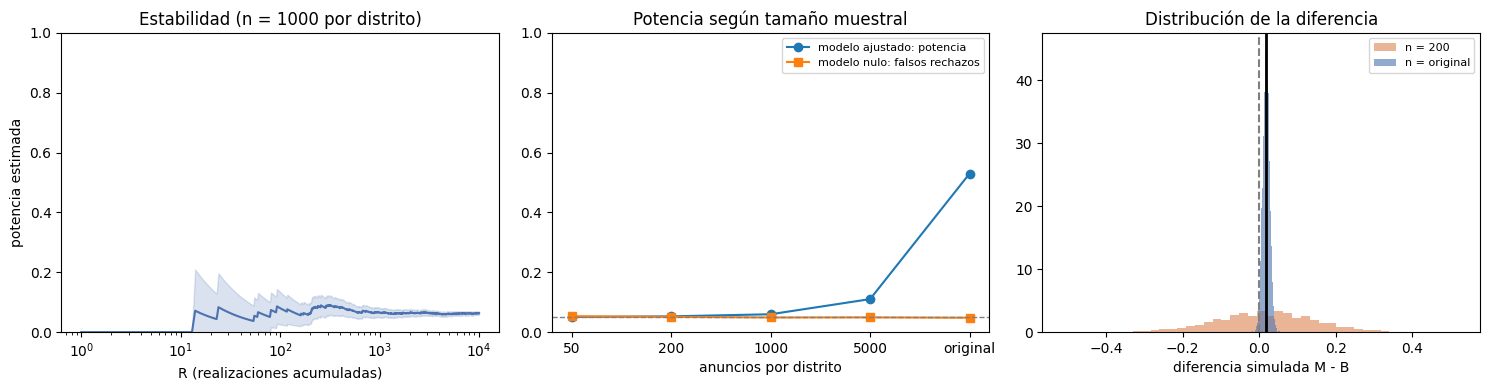

In [9]:
# 9. Estabilidad de Monte Carlo y efecto del tamaño muestral
dif_1000, rech_1000 = simular(1000, 1000, p_m, p_b, R, np.random.default_rng(SEED + 2))
acum = np.cumsum(rech_1000) / np.arange(1, R + 1)
n_ax = np.arange(1, R + 1)
ee_acum = np.sqrt(acum * (1 - acum) / n_ax)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(n_ax, acum, color='#4c72b0')
axes[0].fill_between(n_ax, acum - 2*ee_acum, acum + 2*ee_acum, color='#4c72b0', alpha=0.2)
axes[0].set_ylim(0, 1); axes[0].set_xscale('log')
axes[0].set_xlabel('R (realizaciones acumuladas)'); axes[0].set_ylabel('potencia estimada')
axes[0].set_title('Estabilidad (n = 1000 por distrito)')

axes[1].plot(mc.index, mc['potencia'], 'o-', label='modelo ajustado: potencia')
axes[1].plot(mc.index, mc['falsos_rechazos'], 's-', label='modelo nulo: falsos rechazos')
axes[1].axhline(0.05, color='gray', ls='--', lw=1)
axes[1].set_ylim(0, 1); axes[1].set_xlabel('anuncios por distrito'); axes[1].legend(fontsize=8)
axes[1].set_title('Potencia según tamaño muestral')

for nombre, color in [('200', '#dd8452'), ('original', '#4c72b0')]:
    axes[2].hist(sims[nombre], bins=45, density=True, alpha=0.6, color=color, label=f'n = {nombre}')
axes[2].axvline(0, color='gray', ls='--'); axes[2].axvline(delta, color='k', lw=2)
axes[2].set_xlabel('diferencia simulada M - B'); axes[2].legend(fontsize=8)
axes[2].set_title('Distribución de la diferencia')
fig.tight_layout(); plt.show()

### 5.5 Análisis
- **Potencia:** `potencia` es la probabilidad de detectar la diferencia cuando el modelo dice que existe. Crece con el tamaño muestral, aunque la diferencia real del modelo no cambia.
- **Falsos rechazos:** bajo el modelo nulo deben rondar el 5% (línea punteada); es el control de que la simulación funciona.
- **Precisión:** con pocos anuncios la diferencia estimada se dispersa mucho (puede incluso salir con signo contrario); con muchos se concentra en torno a $\hat\Delta$.

## 6. Interpretación y conclusiones

In [10]:
# 10. Conclusiones con las cifras calculadas
orig = mc.loc['original']; chico = mc.loc['200']
from IPython.display import Markdown, display
display(Markdown(f'''
1. **Estimación.** Las medias son **{mu_m:.4f}** (Manhattan) y **{mu_b:.4f}** (Brooklyn); la diferencia estimada es **{delta:.4f} puntos** en una escala de 1 a 5, con IC95% clásico [{lo_d:.4f}, {hi_d:.4f}]. Es una diferencia muy pequeña en términos prácticos.
2. **Bootstrap vs clásico.** El EE de la diferencia es {ee_delta:.5f} (clásico) y {boot[:,2].std(ddof=1):.5f} (bootstrap), con intervalos casi idénticos. Con muestras grandes y una media como estimador, ambos enfoques coinciden.
3. **Monte Carlo.** Con los tamaños originales, la potencia simulada es **{100*orig['potencia']:.1f}%**; con 200 anuncios por distrito baja a **{100*chico['potencia']:.1f}%**. Detectar una diferencia así de pequeña exige muchos datos, y con muestras pequeñas el signo de la diferencia estimada es poco fiable (P(dif>0) = {100*chico['P(dif>0)']:.1f}% con n=200).
4. **Conexión con la Entrega 1.** La diferencia entre distritos es estadísticamente estimable pero de magnitud pequeña, lo que concuerda con la asociación débil encontrada antes.
'''))


1. **Estimación.** Las medias son **3.2765** (Manhattan) y **3.2585** (Brooklyn); la diferencia estimada es **0.0181 puntos** en una escala de 1 a 5, con IC95% clásico [0.0007, 0.0355]. Es una diferencia muy pequeña en términos prácticos.
2. **Bootstrap vs clásico.** El EE de la diferencia es 0.00888 (clásico) y 0.00883 (bootstrap), con intervalos casi idénticos. Con muestras grandes y una media como estimador, ambos enfoques coinciden.
3. **Monte Carlo.** Con los tamaños originales, la potencia simulada es **53.0%**; con 200 anuncios por distrito baja a **5.3%**. Detectar una diferencia así de pequeña exige muchos datos, y con muestras pequeñas el signo de la diferencia estimada es poco fiable (P(dif>0) = 54.7% con n=200).
4. **Conexión con la Entrega 1.** La diferencia entre distritos es estadísticamente estimable pero de magnitud pequeña, lo que concuerda con la asociación débil encontrada antes.


### Limitaciones
- **Representatividad:** desconocemos cómo se seleccionaron los anuncios del dataset ni por qué faltan algunas calificaciones; los resultados valen para estos datos y no se generalizan sin cuidado al mercado de NYC.
- **Independencia:** supone anuncios independientes; anfitriones con varias propiedades o dependencia espacial alterarían los errores estándar.
- **Asociación, no causalidad:** no controlamos tipo de alojamiento, precio u otras variables.
- **Modelo de Monte Carlo:** fija las probabilidades empíricas y no incorpora la incertidumbre de haberlas estimado.
- **Alcance:** el contraste cubre solo dos de los cinco distritos.

### Referencias
1. Efron, B. (1979). *Bootstrap Methods: Another Look at the Jackknife*. The Annals of Statistics, 7(1), 1–26.
2. Shalizi, C. R. (2018). *Simulation for Inference I — The Bootstrap*. Carnegie Mellon University.
3. NIST. *Monte Carlo Tool*. https://www.nist.gov/services-resources/software/monte-carlo-tool
4. NumPy. *Generator.multinomial*. https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.multinomial.html
5. Airbnb Open Data (NYC), Kaggle: https://www.kaggle.com/datasets/arianazmoudeh/airbnbopendata